# Actividad 3: Representaciones, embeddings y atención

8 %. Equipo.

Avanza con las clases: embeddings tras Clase 7, fundamento neuronal tras Clase 8 y atención tras Clase 10. Reutiliza laboratorios y añade contraste e interpretación propios. No completes atención antes de su explicación.

## Preparación

Coloca `solicitudes.csv` y `apoyo_pln.py` junto a este notebook. El CSV contiene los mensajes y sus particiones; el archivo Python contiene las funciones públicas que usaremos. No necesitas crear carpetas ni cargar un ZIP de recursos.

En Colab, ejecuta la siguiente celda y selecciona los dos archivos cuando aparezca el botón. Si ya los subiste al panel Archivos, se reutilizan. Si Colab elimina la sesión, vuelve a cargarlos.

En local, inicia Jupyter desde la carpeta del notebook y usa un entorno con Python 3.11. Las dependencias están en `requirements.txt`. La práctica utiliza CPU y no necesita claves, MySQL ni descargar modelos.

La celda comprueba los archivos, valida las particiones y prepara los mensajes de entrenamiento. Los ocho pasos de trabajo propio conservan sus instrucciones.


In [1]:
#@title Cargar los archivos de la práctica
from pathlib import Path
import sys

# El CSV y las funciones se buscan en la carpeta actual de la sesión.
ROOT = Path.cwd()
necesarios = ("solicitudes.csv", "apoyo_pln.py")
faltantes = [nombre for nombre in necesarios if not (ROOT / nombre).is_file()]
if faltantes:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Coloca junto al notebook: " + ", ".join(faltantes)) from None
    print("Selecciona los archivos que faltan: " + ", ".join(faltantes))
    files.upload()
faltantes = [nombre for nombre in necesarios if not (ROOT / nombre).is_file()]
if faltantes:
    raise FileNotFoundError("Todavía falta cargar: " + ", ".join(faltantes))
# La ruta explícita permite importar el apoyo sin instalar un paquete del curso.
sys.path.insert(0, str(ROOT))
print("Listo: solicitudes.csv y apoyo_pln.py están en la carpeta de trabajo.")

import platform, time
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from apoyo_pln import words, seed_all, validate_splits, skipgram_embeddings, neighbors
seed_all()
df = pd.read_csv(ROOT / "solicitudes.csv")
validate_splits(df)
train = df[df.split == "train"].copy()
print({"Python": platform.python_version(),
       "paquetes": {p: version(p) for p in ["numpy", "pandas", "torch", "scikit-learn"]},
       "train": len(train)})


Selecciona los archivos que faltan: solicitudes.csv, apoyo_pln.py


Saving apoyo_pln.py to apoyo_pln.py
Saving solicitudes.csv to solicitudes.csv
Listo: solicitudes.csv y apoyo_pln.py están en la carpeta de trabajo.
{'Python': '3.13.18', 'paquetes': {'numpy': '2.4.6', 'pandas': '2.2.3', 'torch': '2.14.1+cpu', 'scikit-learn': '1.6.1'}, 'train': 96}


## Demostración resuelta

Producto=4; normas=2 y √8; cociente=1/√2. Enseña la cuenta sin resolver tu contraste de textos.

In [2]:
u=np.array([2.,0.]);v=np.array([2.,2.])
coseno=(u@v)/(np.linalg.norm(u)*np.linalg.norm(v))
print("Producto:",u@v,"Normas:",np.linalg.norm(u),np.linalg.norm(v),"Coseno:",coseno)
assert np.isclose(coseno,1/np.sqrt(2))


Producto: 4.0 Normas: 2.0 2.8284271247461903 Coseno: 0.7071067811865475


## Paso 1. Entrenar la representación

Usa solo train; declara semilla, ventana, dimensión, épocas y tasa. La función pública aplica el skip-gram desarrollado en Clase 7. Inspecciona vecinos presentes en el vocabulario.

Configuración: {'semilla': 42, 'ventana': 2, 'dim': 16, 'epocas': 40, 'tasa': 0.035}
Vocabulario: 151 tipos | matriz: (151, 16) | pérdida: 5.167 -> 2.326


,factura,pago,vpn,contraseña,red
0,señal (0.602),documento (0.642),desde (0.705),sigue (0.649),pantalla (0.665)
1,equivocado (0.599),factura (0.58),encuentra (0.635),activar (0.594),encuentra (0.624)
2,pago (0.58),señal (0.535),no (0.599),coincide (0.564),conectarme (0.595)
3,casa (0.525),falta (0.517),olvidé (0.572),cotización (0.501),comprobante (0.518)
4,; (0.509),editor (0.509),correo (0.518),saldo (0.464),no (0.488)


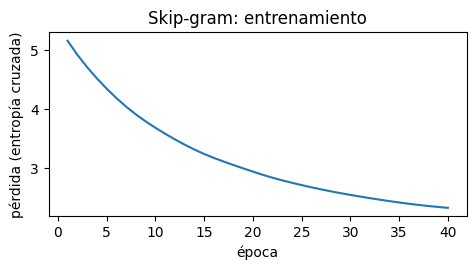

In [3]:
import matplotlib.pyplot as plt

CFG = dict(semilla=42, ventana=2, dim=16, epocas=40, tasa=0.035)
print("Configuración:", CFG)

# Incluir train en vocabulario
vocab, vectores, historia = skipgram_embeddings(train.text, epochs=CFG["epocas"], dim=CFG["dim"])
assert vectores.shape == (len(vocab), CFG["dim"])
print(f"Vocabulario: {len(vocab)} tipos | matriz: {vectores.shape} | "
      f"pérdida: {historia[0]:.3f} -> {historia[-1]:.3f}")

# Vecinos más cercanos de términos en vocabulario
sondas = ["factura", "pago", "vpn", "contraseña", "red"]
display(pd.DataFrame({w: [f"{n} ({s})" for n, s in neighbors(w, vectores, vocab)] for w in sondas}))

plt.figure(figsize=(5, 2.8))
plt.plot(range(1, len(historia) + 1), historia)
plt.xlabel("época"); plt.ylabel("pérdida (entropía cruzada)"); plt.title("Skip-gram: entrenamiento")
plt.tight_layout(); plt.show()

**Mi interpretación:** explica una salida, cómo se obtuvo y su límite.

> La salida obtenida refleja, en la gráfica, un descenso en la pérdida del entrenamiento conforme avanzan las épocas, reflejando un cambio de aproximadamente 5 a 2 en un rango de 40 épocas. Por otro lado, la tabla nos permite ver aciertos puntuales que se dieron debido a que el modelo sí aprendio, algunos de ellos son: `factura` y `pago` que aparecen juntas en 0.58, y `red` muy cerca de `conectarme` en 0.595. Se obtuvo entrenando solo con el vocabulario perteneciente a train y comparando por coseno con los vectores normalizados. El límite de este ejercicio está dado en el corpus, que se conforma de 96 mensajes que repiten 32 frases base con las mismas muletillas y solo 40 épocas, por eso el modelo puede tomar ciertas palabras como vecinos, no refleja un escenario lingüistico real.

## Paso 2. Comparar tres textos

Incluye negación y cambio de orden. Obtén tres pares entre textos; usa las mismas entradas para TF-IDF y promedio. Explica cada celda.

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from itertools import combinations

# Declaración de textos
textos = {
    "Original": "No puedo entrar con el segundo factor.",
    "Negación": "Puedo entrar con el segundo factor.",
    "Orden":    "Con el segundo factor no puedo entrar.",
}
for k, t in textos.items():
    print(f"{k}: {words(t)}")

print("Palabras fuera del vocabulario:", {k: [w for w in words(t) if w not in vocab] for k, t in textos.items()})

# Representaciones de TF-IDF
def coseno(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

def vec_promedio(texto):
    """Promedio de los vectores"""
    return vectores[[vocab.get(w, 1) for w in words(texto)]].mean(axis=0)

def tfidf_ajustado(ngramas):
    """TF-IDF ajustado solo con train y con la misma tokenización"""
    return TfidfVectorizer(tokenizer=words, token_pattern=None, lowercase=False,
                           ngram_range=ngramas).fit(train.text)

tf1, tf2 = tfidf_ajustado((1, 1)), tfidf_ajustado((1, 2))
representaciones = {
    "TF-IDF (1-gramas)": lambda t: tf1.transform([t]).toarray()[0],
    "TF-IDF (1-2 gramas)": lambda t: tf2.transform([t]).toarray()[0],
    "Promedio skip-gram": vec_promedio,
}
etiquetas = {("Original", "Negación"): "(negación)",
             ("Original", "Orden"): "(cambio de orden)",
             ("Negación", "Orden"): "(negación + orden)"}

tabla = pd.DataFrame({
    nombre: {et: coseno(f(textos[a]), f(textos[b])) for (a, b), et in etiquetas.items()}
    for nombre, f in representaciones.items()
})
display(tabla.round(4))


# Diagnóstico
A, B, C = textos.values()
print("Tokens de Original que no están en Negación:", set(words(A)) ^ set(words(B)))
print("Original y orden tienen las mismas palabras:", sorted(words(A)) == sorted(words(C)))

idf = tf1.idf_
print(f"idf('no') = {idf[tf1.vocabulary_['no']]:.3f}  vs  idf mediano del vocabulario = {np.median(idf):.3f}")

bi = lambda t: set(zip(words(t), words(t)[1:]))
print("Bigramas de Original ausentes en Orden:", sorted(bi(A) - bi(C)))



Original: ['no', 'puedo', 'entrar', 'con', 'el', 'segundo', 'factor', '.']
Negación: ['puedo', 'entrar', 'con', 'el', 'segundo', 'factor', '.']
Orden: ['con', 'el', 'segundo', 'factor', 'no', 'puedo', 'entrar', '.']
Palabras fuera del vocabulario: {'Original': [], 'Negación': [], 'Orden': []}


,TF-IDF (1-gramas),TF-IDF (1-2 gramas),Promedio skip-gram
(negación),0.9769,0.9634,0.9829
(cambio de orden),1.0000,0.9026,1.0000
(negación + orden),0.9769,0.8543,0.9829


Tokens de Original que no están en Negación: {'no'}
Original y orden tienen las mismas palabras: True
idf('no') = 1.964  vs  idf mediano del vocabulario = 4.188
Bigramas de Original ausentes en Orden: [('entrar', 'con'), ('factor', '.')]


**Mi interpretación:** explica una salida, cómo se obtuvo y su límite.

> Con 1-gramas y el promedio de embeddings, A–C tiene una similitud de 1.0000 porque solo cambia el orden de las palabras y ambos métodos no toman en cuenta ese orden.&#x20;
>
> La negación tampoco genera mucha diferencia: A–B tiene 0.9769 con TF-IDF y 0.9829 con embeddings. Esto pasa porque «no» representa solo una palabra de las ocho y tiene poco peso en TF-IDF.
>
>Por otro lado, TF-IDF con 1-2 gramas sí detecta algunos cambios en el orden, por lo que la similitud baja (A–C = 0.9026 y B–C = 0.8543). Esto se debe a que cambia la combinación de palabras, como «entrar con» y «factor».
>
>Limitación: Solo se están comparando tres textos y se utiliza un corpus pequeño. Por eso, la diferencia entre 0.977 y 0.983 no es suficiente para decir que un método maneja mejor la negación que otro. Además, que dos frases con significados opuestos tengan una similitud cercana a 0.98 demuestra que ninguna de estas representaciones logra identificar bien la negación.

## Paso 3. Visualizar seis términos

PCA, análisis de componentes principales, reduce coordenadas para dibujar. Explica la pérdida de información y contrasta una relación en los vectores originales.

Varianza explicada por componente: [0.438 0.233] | total 0.671 | perdida 0.329


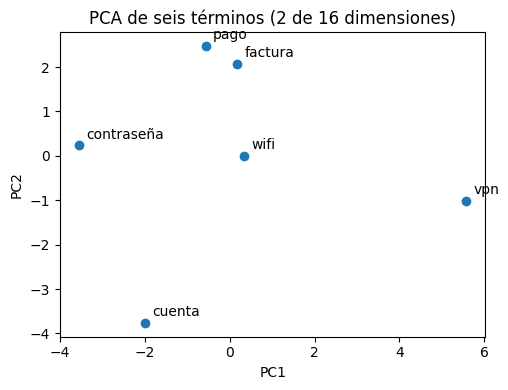

,a,b,coseno_16D,dist_2D
0,contraseña,cuenta,0.291,4.290
1,contraseña,factura,0.160,4.158
2,contraseña,pago,0.253,3.740
3,contraseña,wifi,0.071,3.906
4,contraseña,vpn,-0.284,9.213
5,cuenta,factura,-0.009,6.226
6,cuenta,pago,-0.040,6.396
7,cuenta,wifi,0.204,4.426
8,cuenta,vpn,-0.056,8.051
9,factura,pago,0.580,0.833


Spearman(coseno_16D, -dist_2D): 0.796
Inversiones de orden: 11 de 60 comparaciones (pares con un término en común)
  contraseña: (contraseña,cuenta) cos=0.291 d2D=4.29  vs  (contraseña,wifi) cos=0.071 d2D=3.91
  wifi: (contraseña,wifi) cos=0.071 d2D=3.91  vs  (cuenta,wifi) cos=0.204 d2D=4.43
  wifi: (contraseña,wifi) cos=0.071 d2D=3.91  vs  (wifi,vpn) cos=0.203 d2D=5.33


In [21]:
from itertools import combinations
from sklearn.decomposition import PCA

terminos = ["contraseña", "cuenta", "factura", "pago", "wifi", "vpn"]
X = np.array([vectores[vocab[t]] for t in terminos])            # (6, 16): vectores originales
pca = PCA(n_components=2).fit(X)
Z = pca.transform(X)                                            # (6, 2): solo para dibujar
perdida = 1 - pca.explained_variance_ratio_.sum()
print("Varianza explicada por componente:", pca.explained_variance_ratio_.round(3),
      f"| total {pca.explained_variance_ratio_.sum():.3f} | perdida {perdida:.3f}")

plt.figure(figsize=(5.2, 4))
plt.scatter(Z[:, 0], Z[:, 1])
for (x, y), t in zip(Z, terminos):
    plt.annotate(t, (x, y), textcoords="offset points", xytext=(5, 5))
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA de seis términos (2 de 16 dimensiones)")
plt.tight_layout(); plt.show()

# Coseno en los 16 vectores originales vs distancia euclídea en el plano para comparar
U = X / np.linalg.norm(X, axis=1, keepdims=True)
pares = pd.DataFrame([(terminos[i], terminos[j], float(U[i] @ U[j]), float(np.linalg.norm(Z[i] - Z[j])))
                      for i, j in combinations(range(len(terminos)), 2)],
                     columns=["a", "b", "coseno_16D", "dist_2D"])
display(pares.round(3))
print("Spearman(coseno_16D, -dist_2D):", round(pares.coseno_16D.corr(-pares.dist_2D, method="spearman"), 3))

# Dos pares que comparten un término y cuyo orden cambia entre 16D y 2D
inv, comparables = [], 0
for (_, r1), (_, r2) in combinations(pares.iterrows(), 2):
    comun = {r1.a, r1.b} & {r2.a, r2.b}
    if len(comun) != 1:
        continue
    comparables += 1
    if (r1.coseno_16D - r2.coseno_16D) * (r2.dist_2D - r1.dist_2D) < 0:
        inv.append((abs(r1.coseno_16D - r2.coseno_16D), comun.pop(), r1, r2))
print(f"Inversiones de orden: {len(inv)} de {comparables} comparaciones (pares con un término en común)")
for _, t, r1, r2 in sorted(inv, key=lambda z: -z[0])[:3]:
    print(f"  {t}: ({r1.a},{r1.b}) cos={r1.coseno_16D:.3f} d2D={r1.dist_2D:.2f}  vs  "
          f"({r2.a},{r2.b}) cos={r2.coseno_16D:.3f} d2D={r2.dist_2D:.2f}")


**Mi interpretación:** explica una salida, cómo se obtuvo y su límite.

> Los primeros dos componentes de PCA explican el 67.1 % de la varianza (43.8 % + 23.3 %), por lo que el dibujo deja fuera el 32.9 % restante.
>
> Para comprobar qué tan bien representa el dibujo los datos originales, se compararon las distancias entre los 15 pares de palabras en sus 16 dimensiones originales y en el plano de PCA.
>
> Algunas relaciones se mantienen, como `factura` y `pago`, que son las palabras más cercanas en ambos espacios (coseno de 0.580 y distancia de 0.83). Sin embargo, otras cambian. Por ejemplo, `contraseña` tiene mayor similitud con `cuenta` (0.291) que con `wifi` (0.071), pero en el dibujo aparece más cerca de `wifi` (3.91) que de `cuenta` (4.29).
>
> En total hubo 11 cambios de este tipo y la correlación de Spearman fue de 0.796. Esto indica que el dibujo conserva parte de las relaciones originales, pero no todas.
>
>Limitación: Solo se tienen seis palabras y dos componentes que no tienen un significado específico por sí mismos. Además, la distancia euclídea y el coseno miden cosas diferentes, por lo que no todas las diferencias se deben a PCA. También hay que considerar que los vectores originales ya tenían cierto ruido desde el paso 1.

## Paso 4. Cambiar una variable

Cambia dimensión o contexto conservando los otros ajustes. Una perturbación queda separada del corpus original. No alteres archivos ni particiones.

In [22]:
import apoyo_pln as ap

huella = pd.util.hash_pandas_object(df, index=True).sum()   # para comprobar que df no se altera
SONDAS = ["factura", "pago", "vpn", "contraseña", "red", "tarjeta", "archivo", "wifi"]

def entrenar(dim, semilla=42):
    """skip-gram con las mismas épocas; solo cambia dim"""
    previo = ap.seed_all.__defaults__
    ap.seed_all.__defaults__ = (semilla, True)       # skipgram_embeddings llama seed_all() sin argumentos
    try:
        return skipgram_embeddings(train.text, epochs=CFG["epocas"], dim=dim)
    finally:
        ap.seed_all.__defaults__ = previo

def vecinos(res, k=5):
    v, m, _ = res
    return {w: {n for n, _ in neighbors(w, m, v, k=k)} for w in SONDAS}

def solape(r1, r2, k=5):
    a, b = vecinos(r1, k), vecinos(r2, k)
    return float(np.mean([len(a[w] & b[w]) / k for w in SONDAS]))

base = entrenar(16)
filas = []
for dim in [4, 8, 16, 32, 64]:                       # variable cambiada: dimensión (semilla 42 fija)
    r = base if dim == 16 else entrenar(dim)
    filas.append(("dimensión", dim, 42, r[2][-1], solape(base, r)))
for s in [1, 2, 3, 4, 7]:                            # control: misma dimensión, otra semilla
    r = entrenar(16, s)
    filas.append(("control semilla", 16, s, r[2][-1], solape(base, r)))
resultado = pd.DataFrame(filas, columns=["factor", "dim", "semilla", "pérdida final", "solape vecinos (top-5)"])
display(resultado.round(3))

ctrl = resultado[resultado.factor == "control semilla"]
print(f"Ruido por semilla (dim=16): pérdida {ctrl['pérdida final'].min():.3f}-{ctrl['pérdida final'].max():.3f}, "
      f"solape {ctrl['solape vecinos (top-5)'].min():.3f}-{ctrl['solape vecinos (top-5)'].max():.3f}")

assert pd.util.hash_pandas_object(df, index=True).sum() == huella   # corpus y particiones intactos


,factor,dim,semilla,pérdida final,solape vecinos (top-5)
0,dimensión,4,42,3.757,0.000
1,dimensión,8,42,3.006,0.150
2,dimensión,16,42,2.326,1.000
3,dimensión,32,42,2.116,0.175
4,dimensión,64,42,2.081,0.150
5,control semilla,16,1,2.326,0.125
6,control semilla,16,2,2.323,0.100
7,control semilla,16,3,2.308,0.075
8,control semilla,16,4,2.319,0.125
9,control semilla,16,7,2.350,0.075


Ruido por semilla (dim=16): pérdida 2.308-2.350, solape 0.075-0.125


**Mi interpretación:** explica una salida, cómo se obtuvo y su límite.

> Solo cambié la dimensión de los vectores (4, 8, 16, 32 y 64), manteniendo las mismas 40 épocas, el mismo corpus y la semilla 42.
>
> La pérdida de entrenamiento disminuye conforme aumenta la dimensión: 3.757, 3.006, 2.326, 2.116 y 2.081. Sin embargo, la mejora es cada vez menor. También probé diferentes semillas con dimensión 16 y la pérdida solo cambió entre 2.308 y 2.350, por lo que las diferencias principales sí parecen depender de la dimensión.
>
> Con los vecinos más cercanos pasó algo diferente. Al comparar los top-5, el solapamiento con el modelo base fue de 0.000 a 0.175 al cambiar la dimensión y de 0.075 a 0.125 al cambiar la semilla. Esto significa que los vecinos cambian bastante incluso con modificaciones pequeñas, así que no puedo asegurar que esos cambios se deban únicamente a la dimensión.
>
> Limitación: Tener una pérdida menor no significa necesariamente que los vectores sean mejores. Al aumentar las dimensiones, el modelo puede ajustarse mejor al corpus de 96 mensajes, pero también puede memorizar los datos. Además, solo probé 8 palabras y 5 semillas. El corpus y sus particiones se mantuvieron iguales durante las pruebas, lo cual comprobé con una huella del DataFrame.

## Paso 5. Desarrollar atención

Con Q=[[1,0]], K=[[1,0],[0,1]], V=[[2,0],[0,4]], muestra producto, escala, exponenciales, normalización y salida. Indica formas y conserva precisión.

In [29]:
import math

# D1: entradas del mecanismo (float64 para conservar precisión).
Q = torch.tensor([[1., 0.]], dtype=torch.float64)
K = torch.tensor([[1., 0.], [0., 1.]], dtype=torch.float64)
V = torch.tensor([[2., 0.], [0., 4.]], dtype=torch.float64)
dk = Q.shape[-1]

producto = Q @ K.T                                   # (1, 2)
scores = producto / math.sqrt(dk)                    # (1, 2)  escala 1/sqrt(dk)

# D2: exponenciales, normalización y mezcla.
exp_directa = torch.exp(scores)
exp_estable = torch.exp(scores - scores.max(dim=-1, keepdim=True).values)
pesos = exp_estable / exp_estable.sum(dim=-1, keepdim=True)
salida = pesos @ V                                   # (1, 2)

torch.set_printoptions(precision=10, sci_mode=False)
print("Formas Q, K, V:", tuple(Q.shape), tuple(K.shape), tuple(V.shape),
      "| producto:", tuple(producto.shape), "| pesos:", tuple(pesos.shape), "| salida:", tuple(salida.shape))
display(pd.DataFrame({"clave": ["posición 1", "posición 2"], "producto": producto[0].numpy(),
                      "score_escalado": scores[0].numpy(), "exp_directa": exp_directa[0].numpy(),
                      "exp_estable": exp_estable[0].numpy(), "peso": pesos[0].numpy()}))
print("Suma de pesos:", pesos.sum(dim=-1).item(), "| Salida de la mezcla:", salida)

w1 = math.exp(1 / math.sqrt(2)) / (math.exp(1 / math.sqrt(2)) + 1)      # forma cerrada del primer peso
assert torch.allclose(pesos, torch.softmax(scores, dim=-1), atol=1e-12, rtol=0)
assert torch.allclose(salida, torch.tensor([[2 * w1, 4 * (1 - w1)]], dtype=torch.float64), atol=1e-12, rtol=0)

# D3: excluir la segunda clave ANTES de normalizar.
bloqueado = scores.clone()
bloqueado[:, 1] = float("-inf")
pesos_mask = torch.softmax(bloqueado, dim=-1)
salida_mask = pesos_mask @ V
print("\nScores con exclusión:", bloqueado, "| pesos:", pesos_mask, "| salida:", salida_mask)

mal = pesos.clone(); mal[:, 1] = 0                   # error deliberado: poner 0 después de normalizar
print("Contraste incorrecto: suma =", mal.sum().item(), "| mezcla =", mal @ V)
assert torch.allclose(pesos_mask, torch.tensor([[1., 0.]], dtype=torch.float64))
assert torch.allclose(salida_mask, torch.tensor([[2., 0.]], dtype=torch.float64))


Formas Q, K, V: (1, 2) (2, 2) (2, 2) | producto: (1, 2) | pesos: (1, 2) | salida: (1, 2)


,clave,producto,score_escalado,exp_directa,exp_estable,peso
0,posición 1,1.0,0.707107,2.028115,1.000000,0.669762
1,posición 2,0.0,0.000000,1.000000,0.493069,0.330238


Suma de pesos: 1.0 | Salida de la mezcla: tensor([[1.3395230987, 1.3209538027]], dtype=torch.float64)

Scores con exclusión: tensor([[0.7071067812,         -inf]], dtype=torch.float64) | pesos: tensor([[1., 0.]], dtype=torch.float64) | salida: tensor([[2., 0.]], dtype=torch.float64)
Contraste incorrecto: suma = 0.6697615493266569 | mezcla = tensor([[1.3395230987, 0.0000000000]], dtype=torch.float64)


**Mi interpretación:** explica una salida, cómo se obtuvo y su límite.

> Usé Q=[[1,0]], K=[[1,0],[0,1]] y V=[[2,0],[0,4]], con dimensiones 1×2, 2×2 y 2×2, respectivamente.
>
> Primero calculé QKᵀ, obteniendo [1, 0]. Después dividí entre √2 y obtuve [0.7071, 0]. Al aplicar exponencial, los resultados fueron [2.0281, 1.0] y, después de softmax, los pesos fueron [0.6698, 0.3302], que suman 1. Finalmente, al mezclar los valores con esos pesos, obtuve [1.3395, 1.3210], con forma 1×2.
>
> También probé `exp_estable`, que consiste en restar el valor máximo antes de aplicar exponencial. Aunque los resultados cambiaron a [1.0, 0.4931], los pesos se mantuvieron iguales.
>
> Al bloquear la segunda clave con −∞ antes de normalizar, los pesos fueron [1, 0] y la salida [2, 0]. En cambio, si se coloca 0 después de normalizar, la suma de los pesos queda en 0.6698 y la salida es [1.3395, 0], por lo que deja de ser una distribución válida.
>
> Limitación: Se utilizaron valores elegidos manualmente y no texto real. Además, un peso de 0.6698 indica cuánto contribuye el primer valor a la mezcla, pero no significa que exista un 67 % de certeza ni explica por qué se obtuvo ese resultado.

## Paso 6. Comprobar tres posiciones causales

Una posición consulta pasado y a sí misma. Aplica máscara antes de softmax; revisa zona superior y sumas.

In [30]:
from apoyo_pln import attention

torch.set_printoptions(precision=6, sci_mode=False)
I3 = torch.eye(3)                                    # Q = K = V = I (3 x 3): tres posiciones
_, a = attention(I3, I3, I3, causal=True)
etiquetas = ["posición 1", "posición 2", "posición 3"]
display(pd.DataFrame(a.numpy(), index=etiquetas, columns=etiquetas))

futuro = torch.triu(torch.ones(3, 3, dtype=torch.bool), diagonal=1)      # True = bloquear
print("Máscara (True = futuro):\n", futuro.int())
print("Zona superior:", a[futuro].tolist(), "| sumas por fila:", a.sum(dim=-1).tolist())

# Fila 2 a mano: scores = [0, 1, 0] / sqrt(3); la clave 3 se bloquea antes de softmax
fila2 = torch.tensor([0., 1 / math.sqrt(3), float("-inf")])
print("Fila 2 a mano:", torch.softmax(fila2, dim=-1).tolist())
assert torch.allclose(torch.softmax(fila2, dim=-1), a[1], atol=1e-6)
assert torch.allclose(a.sum(dim=-1), torch.ones(3), atol=1e-6) and torch.count_nonzero(a[futuro]) == 0

# Contraste: enmascarar DESPUÉS de softmax deja filas que ya no suman 1
mal = torch.softmax(I3 @ I3.T / math.sqrt(3), dim=-1).masked_fill(futuro, 0.0)
print("Máscara después de softmax -> sumas por fila:", mal.sum(dim=-1).tolist())


,posición 1,posición 2,posición 3
posición 1,1.000000,0.000000,0.000000
posición 2,0.359542,0.640457,0.000000
posición 3,0.264458,0.264458,0.471083


Máscara (True = futuro):
 tensor([[0, 1, 1],
        [0, 0, 1],
        [0, 0, 0]], dtype=torch.int32)
Zona superior: [0.0, 0.0, 0.0] | sumas por fila: [1.0, 0.9999999403953552, 0.9999999403953552]
Fila 2 a mano: [0.35954248905181885, 0.6404574513435364, 0.0]
Máscara después de softmax -> sumas por fila: [0.47108304500579834, 0.7355414628982544, 0.9999999403953552]


**Mi interpretación:** explica una salida, cómo se obtuvo y su límite.

> Usé Q=K=V=I (matrices de identidad de 3×3). Los pesos de atención causal fueron [1, 0, 0], [0.3595, 0.6405, 0] y [0.2645, 0.2645, 0.4711].
>
> La parte superior de la matriz tiene valores de cero y cada fila suma 1 (con una tolerancia de 1e-6 por el uso de float32). Esto significa que cada posición solo puede repartir su atención entre las posiciones anteriores y ella misma.
>
> Para conseguirlo, coloqué −∞ en las posiciones futuras antes de aplicar softmax. También comprobé manualmente la segunda fila con softmax([0, 0.5774]), obteniendo [0.3595, 0.6405], que coincide con el resultado.
>
> Los pesos de las posiciones permitidas no son iguales. Por ejemplo, en la tercera fila, las posiciones 1 y 2 tienen el mismo peso (0.2645), mientras que la posición 3 tiene uno mayor (0.4711) porque su puntuación también es mayor.
>
> En cambio, al aplicar la máscara después de softmax, las filas suman 0.4711, 0.7355 y 1.0. Esto sucede porque las posiciones futuras ya se habían incluido en el cálculo de la normalización.
>
> Limitación: Un valor de cero en la matriz significa que una posición está bloqueada, no que tenga poca relevancia. Además, en este ejemplo la salida coincide con los pesos únicamente porque V es una matriz identidad.

## Paso 7. Inspeccionar el bloque

Usa el bloque pequeño de Clase 10. Declara lote, longitud, coordenadas y cabezas. Comprueba formas sin entrenar otro modelo.

In [31]:
# Lote, longitud, coordenadas y cabezas declarados
B, T, D, H = 2, 4, 12, 3
torch.manual_seed(42)
block = torch.nn.TransformerEncoderLayer(
    d_model=D, nhead=H, dim_feedforward=24, dropout=0,
    batch_first=True, activation="relu", norm_first=False)
inputs = torch.randn(B, T, D)
position = torch.arange(T).view(1, T, 1) / 10 * torch.linspace(1, 2, D)
mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)      # True = bloquear
block.eval()                                                          # sin entrenar: solo inspección

with torch.no_grad():
    z = inputs + position
    outputs = block(z, src_mask=mask)
    # D7: reconstrucción atención -> residual -> norma -> FFN -> residual -> norma
    atencion, pesos_cab = block.self_attn(z, z, z, attn_mask=mask, need_weights=True,
                                          average_attn_weights=False)
    tras_atencion = block.norm1(z + block.dropout1(atencion))
    ffn = block.linear2(block.dropout(block.activation(block.linear1(tras_atencion))))
    reconstruido = block.norm2(tras_atencion + block.dropout2(ffn))

print(f"lote B={B}, longitud T={T}, coordenadas D={D}, cabezas h={H}, coordenadas por cabeza={D // H}, FFN {D}->24->{D}")
display(pd.DataFrame({"tensor": ["entrada", "posición", "máscara", "pesos por cabeza", "tras atención", "salida"],
                      "forma": [tuple(t.shape) for t in (inputs, position, mask, pesos_cab, tras_atencion, outputs)]}))
print("Parámetros del bloque:", sum(p.numel() for p in block.parameters()),
      "| diferencia máxima al reconstruir:", (reconstruido - outputs).abs().max().item())

assert outputs.shape == inputs.shape and pesos_cab.shape == (B, H, T, T)
assert torch.all(torch.triu(pesos_cab, diagonal=1) == 0)
assert torch.allclose(pesos_cab.sum(dim=-1), torch.ones(B, H, T), atol=1e-6)
assert torch.allclose(reconstruido, outputs, atol=1e-6, rtol=0)


lote B=2, longitud T=4, coordenadas D=12, cabezas h=3, coordenadas por cabeza=4, FFN 12->24->12


,tensor,forma
0,entrada,"(2, 4, 12)"
1,posición,"(1, 4, 12)"
2,máscara,"(4, 4)"
3,pesos por cabeza,"(2, 3, 4, 4)"
4,tras atención,"(2, 4, 12)"
5,salida,"(2, 4, 12)"


Parámetros del bloque: 1284 | diferencia máxima al reconstruir: 2.384185791015625e-07


**Mi interpretación:** explica una salida, cómo se obtuvo y su límite.

> Usé un lote de 2, una secuencia de 4 elementos, 12 dimensiones y 3 cabezas de atención (4 dimensiones por cabeza). Tanto la entrada como la salida tienen forma (2, 4, 12), mientras que los pesos de atención por cabeza tienen forma (2, 3, 4, 4). Aunque las dimensiones se mantienen, los valores sí cambian. El bloque tiene 1284 parámetros y no fue entrenado.
>
> La atención es la primera parte del bloque y se encarga de mezclar información entre las diferentes posiciones. Después se aplica una conexión residual, LayerNorm y una red FFN (12→24→12). Finalmente, se vuelve a aplicar otra conexión residual y LayerNorm.
>
> Reconstruí todo el proceso utilizando las partes del propio bloque y obtuve una diferencia de apenas 2.4e-7 respecto a `outputs`, dentro de la tolerancia de 1e-6. También comprobé que los pesos sumaran 1 por fila y cabeza, y que la parte superior de la matriz fuera cero por la máscara causal.
>
> Limitación: Los pesos son aleatorios, por lo que esta comprobación demuestra que las operaciones y las dimensiones son correctas, pero no que el modelo tenga un buen desempeño lingüístico. Además, es un bloque de autoatención con FFN, no un decodificador completo, ya que no incluye atención cruzada.

## Paso 8. Modificar un token futuro

Mantén pesos y desactiva dropout. Cambia una coordenada futura y compara posiciones previas con máscara. Contrasta acceso sin máscara.

In [32]:
inputs_e1 = inputs.clone()
inputs_e1[:, -1, 0] += 10
assert (inputs_e1 - inputs).abs().sum().item() == 10 * B

def corrida(x, src_mask):
    with torch.no_grad():
        return block(x + position, src_mask=src_mask)

def diferencia_por_posicion(src_mask):
    return (corrida(inputs_e1, src_mask) - corrida(inputs, src_mask)).abs().amax(dim=(0, 2))

dif_con, dif_sin = diferencia_por_posicion(mask), diferencia_por_posicion(None)
display(pd.DataFrame({"con máscara causal": dif_con.numpy(), "sin máscara": dif_sin.numpy()},
                      index=[f"posición {i + 1}" + (" (modificada)" if i == T - 1 else "") for i in range(T)]))
print("Máx. diferencia en posiciones 1-3 con máscara causal:", dif_con[:-1].max().item())
print("Máx. diferencia en posiciones 1-3 sin máscara:       ", dif_sin[:-1].max().item())

assert dif_con[:-1].max().item() == 0.0              # con máscara, el pasado no cambia
assert (dif_sin[:-1] > 1e-6).all()                   # sin máscara, todas las previas cambian


,con máscara causal,sin máscara
posición 1,0.000000,1.251772
posición 2,0.000000,1.122762
posición 3,0.000000,0.800644
posición 4 (modificada),2.858745,2.858745


Máx. diferencia en posiciones 1-3 con máscara causal: 0.0
Máx. diferencia en posiciones 1-3 sin máscara:        1.2517716884613037


**Mi interpretación:** explica una salida, cómo se obtuvo y su límite.

> Conservé el bloque del paso 7 con los mismos pesos, `eval()` y dropout desactivado. Después, hice una copia de `inputs` y sumé 10 a la coordenada 0 de la última posición de cada secuencia.
>
> Con la máscara causal, las posiciones anteriores (1–3) no cambian (diferencia máxima de 0.0). En cambio, sin la máscara sí cambian: 1.2518, 1.1228 y 0.8006, respectivamente.
>
> La última posición (4), que fue la modificada, cambia 2.8587 en ambos casos porque puede acceder a sí misma.
>
> Esto permite comprobar la diferencia entre las dos configuraciones: con máscara causal, cada posición solo puede acceder a las anteriores y a sí misma; sin máscara, puede acceder a toda la secuencia, incluido el futuro.
>
> Modifiqué una sola coordenada porque cambiar todas por igual podría hacer que la normalización eliminara parte de la diferencia.
>
> Limitación: Es una sola perturbación sobre un bloque que no fue entrenado. La prueba demuestra a qué información puede acceder cada posición, pero no explica las decisiones del modelo. Tampoco basta con observar los pesos de atención para conocer qué información determina una decisión.

## Cierre y entrega

Notebook con comparación de representaciones, experimento de contexto, matrices de atención, verificación numérica y conclusiones. Reutiliza los cálculos de laboratorio y añade el contraste y la interpretación propios de la actividad.

- Comparación de representaciones: 25 puntos. Compara métodos sobre los mismos textos y explica diferencias.
- Cálculo numérico de atención: 30 puntos. Muestra scores escalados, softmax y salida con comprobación.
- Dimensiones y máscara: 20 puntos. Identifica formas y demuestra qué posiciones se excluyen.
- Experimento de cambio: 15 puntos. Modifica una variable y atribuye el efecto sin confundir factores.
- Decisión y límites: 10 puntos. Justifica la representación y distingue atención de explicación causal.

Conserva README y archivos pertinentes; no se añade otro informe.

> ¿Qué recibió el cálculo?
>
> En los pasos 1–4 se utilizaron los 96 mensajes de `train`, con los que se entrenó el modelo skip-gram de 16 dimensiones, además de tres textos para comparar los resultados.
>
> En los pasos 5–8 se utilizaron números elegidos manualmente (Q, K y V, y una matriz identidad de 3×3), además de un lote aleatorio de tamaño 2×4×12 con una señal de posición. Este último se procesó con un `TransformerEncoderLayer` sin entrenar.
>
> ¿Qué transformó?
>
> Los textos se convirtieron en representaciones TF-IDF, vectores skip-gram y promedios de embeddings. Después, PCA redujo seis términos a dos dimensiones para poder visualizarlos.
>
> En la parte de atención, se compararon las consultas con las claves mediante QKᵀ, se dividieron los resultados entre √dk y se aplicó softmax para obtener los pesos. Finalmente, estos pesos se utilizaron para combinar los valores mediante `pesos @ V`. Las máscaras se aplicaron colocando −∞ antes de softmax.
>
> Dentro del bloque Transformer, la atención mezcla información entre posiciones y después se aplican las conexiones residuales, LayerNorm y la FFN.
>
> ¿Qué devolvió?
>
> En la parte de texto, se obtuvieron las similitudes entre los tres pares de frases. A–C tuvo un coseno de 1.0000 con TF-IDF de 1-gramas y con el promedio de embeddings. El modelo skip-gram redujo su pérdida de 5.167 a 2.326, aunque sus vecinos cambiaron al modificar la dimensión o la semilla.
>
> En la parte de atención, se obtuvieron resultados como [1.3395, 1.3210] y [2, 0] al bloquear la segunda clave. También se comprobaron los pesos causales, la salida de forma (2, 4, 12) y las diferencias al modificar la última posición: 0.0 con máscara causal y hasta 1.2518 sin ella.
>
> ¿Qué demuestra la comprobación?
>
> Que los pesos de atención suman 1, que las posiciones bloqueadas tienen peso 0 y que el cálculo manual de softmax coincide con el de PyTorch. También se comprobó que la reconstrucción del bloque produce prácticamente la misma salida.
>
> En los experimentos con texto se observó que las bolsas de palabras no distinguen el orden de las palabras y que la negación casi no afecta la similitud (0.977–0.983). Además, cambiar la dimensión afecta más la pérdida que cambiar la semilla, cuya variación fue de 2.308 a 2.350.
>
> Por último, se comprobó que con máscara causal modificar información futura no altera las posiciones anteriores, mientras que sin máscara sí lo hace.
>
> ¿Qué no demuestra?
>
> Estos experimentos no demuestran comprensión ni calidad lingüística. El corpus contiene solo 96 mensajes que repiten ciertas estructuras, por lo que los vecinos obtenidos no representan necesariamente relaciones semánticas reales. Además, los pesos del bloque Transformer son aleatorios y no fueron entrenados.
>
> Un peso de atención indica cuánto participa un valor en una mezcla, pero no representa un porcentaje de certeza ni explica por sí solo una decisión del modelo. Finalmente, el término «causal» en la máscara se refiere al orden de la secuencia, no a una relación de causa y efecto.